# Notebook to visualise the results

In [46]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import h5py
from matplotlib.gridspec import GridSpec
from utils.naming import *
from pipeline_pre_ADI.pre_process.pre_processing import radial_profile_pre

## Visualise the processed data

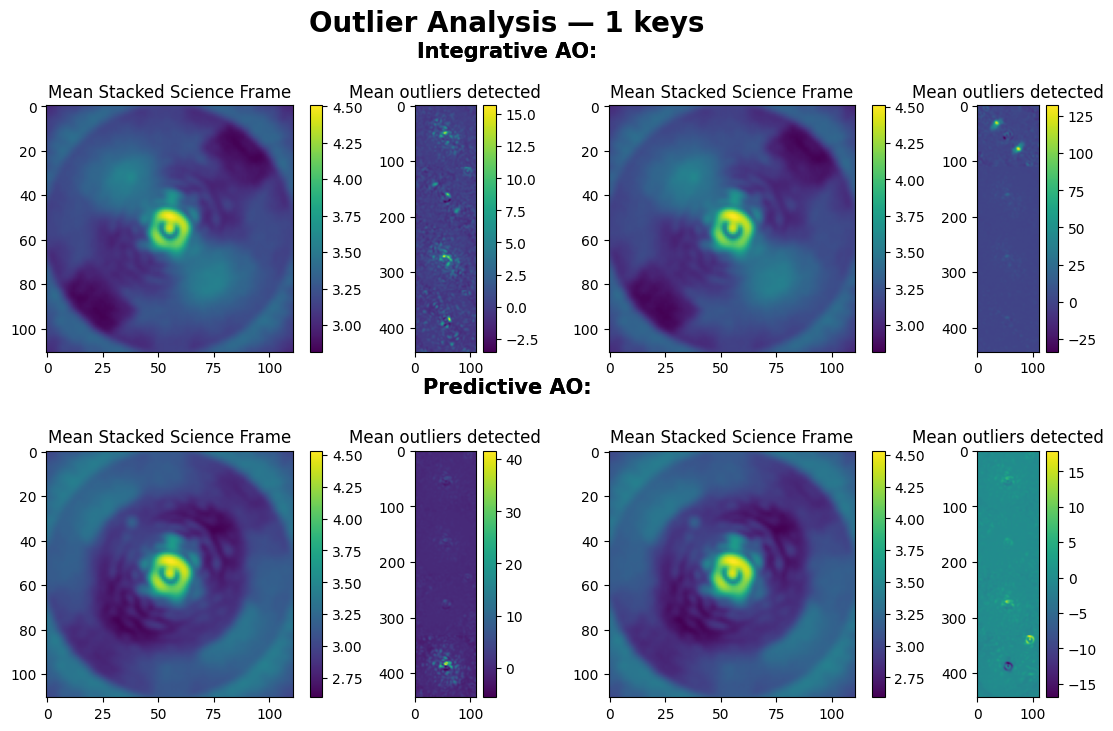

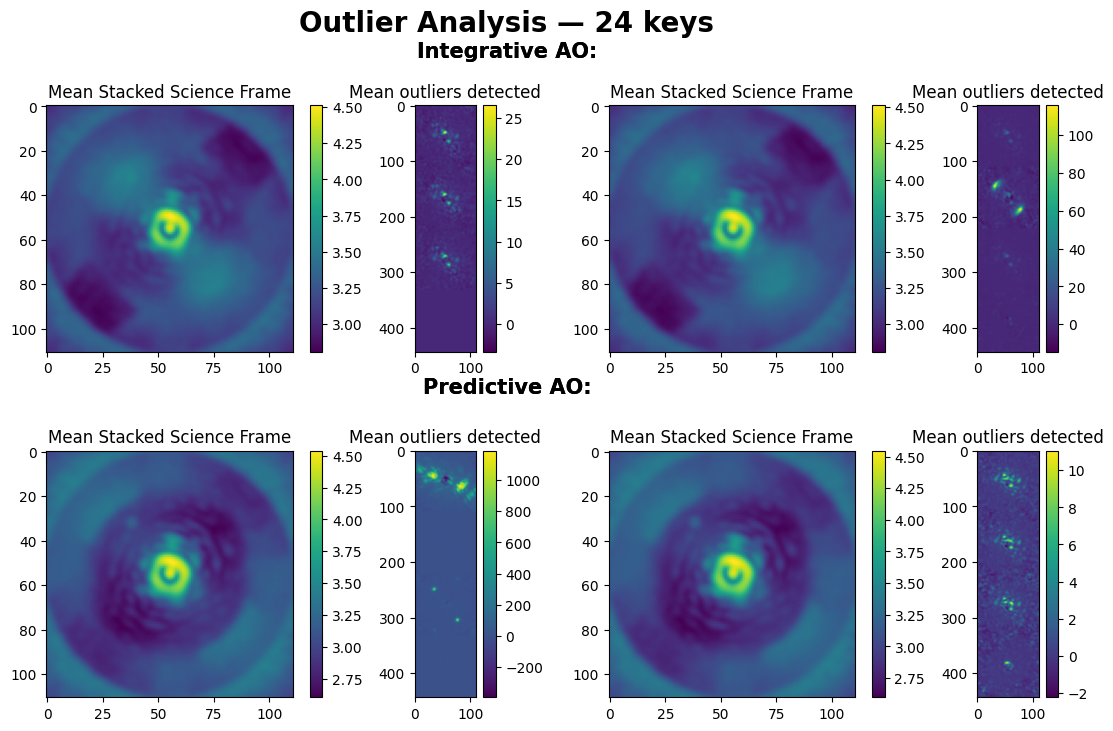

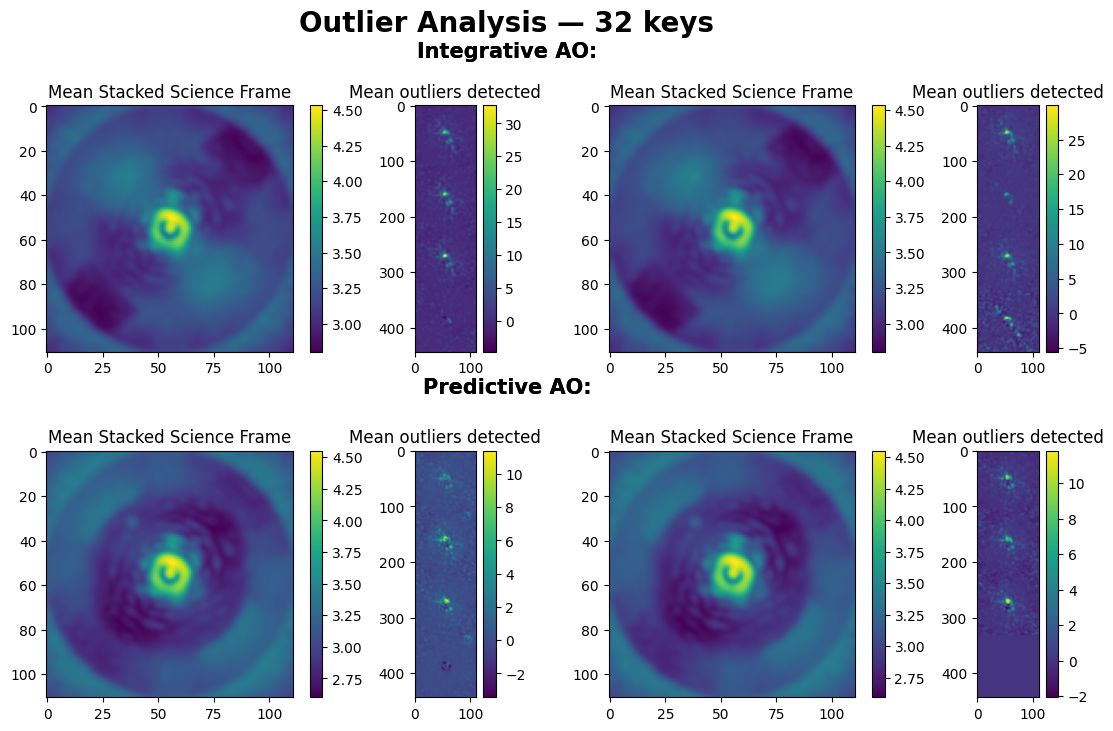

In [45]:
ori_folder = "/home/aosimul/noah/data/ghost_images/long_7ro_20ws/"
name = "_7ro_20ws_"

h5 = h5py.File(
    "/home/aosimul/noah/src/pipeline_pre_ADI/results/long_7ro_20ws/outlier_diff.h5", "r"
)

try:
    for key in [1, 24, 32]:
        fig = plt.figure(figsize=(14, 8))

        gs = GridSpec(
            2,
            8,
            figure=fig,
            width_ratios=[3, 3, 1, 1, 3, 3, 1, 1],
            height_ratios=[1, 1],
            hspace=0.4,
            wspace=0.4,
            top=0.85,
        )

        fig.suptitle(
            f"Outlier Analysis — {key} keys", fontsize=20, fontweight="bold", y=0.97
        )

        for j, batch in enumerate(["_1-4", "_5-8"]):
            for i, ds in enumerate(["int", "pred"]):
                filename = f"{ds}{name}{key}key"

                stack = np.load(f"{ori_folder}{filename}{batch}.npy")
                mean = np.mean(stack, axis=0)

                # Row title
                fig.text(
                    0.5,
                    0.91 - i * 0.42,
                    titling(ds),
                    ha="center",
                    fontsize=15,
                    fontweight="bold",
                )

                # Mean science frame: wider
                ax1 = fig.add_subplot(gs[i, j * 4 : j * 4 + 2])
                im1 = ax1.imshow(np.log10(mean))
                ax1.set_title("Mean Stacked Science Frame")
                fig.colorbar(im1, ax=ax1, fraction=0.04)

                # Outliers: narrower
                outliers = np.concatenate(
                    [h5[f"{filename}_{n + j * 4}"][:] for n in range(1, 5)]
                )

                ax2 = fig.add_subplot(gs[i, j * 4 + 2 : j * 4 + 4])
                im2 = ax2.imshow(outliers)
                ax2.set_title("Mean outliers detected")
                fig.colorbar(im2, ax=ax2)

        plt.show()

finally:
    h5.close()

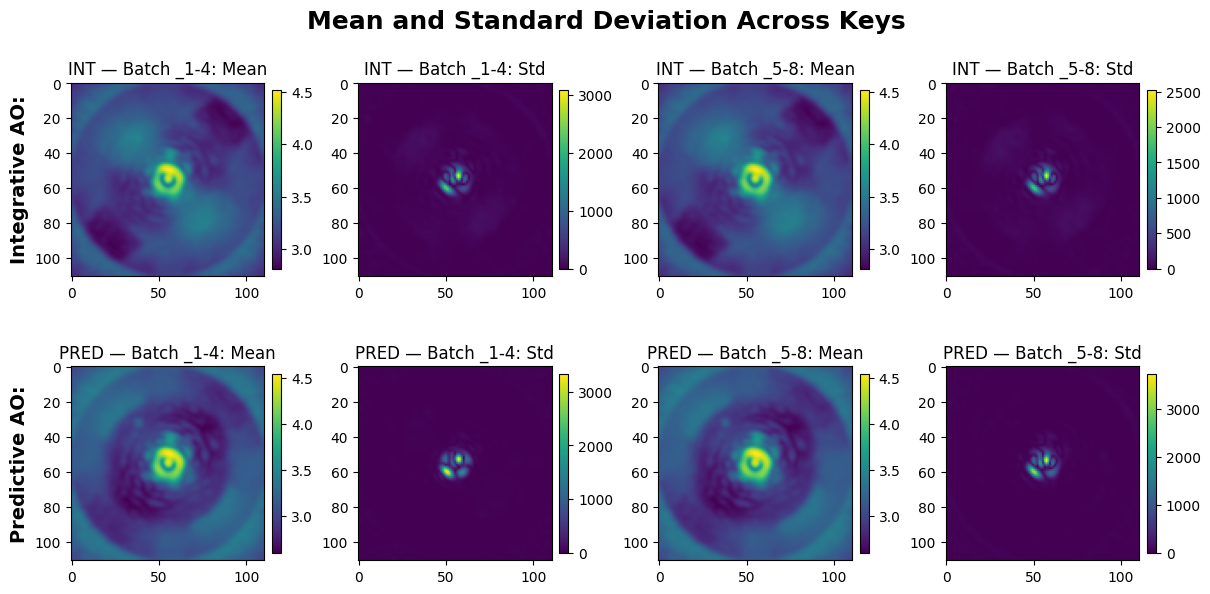

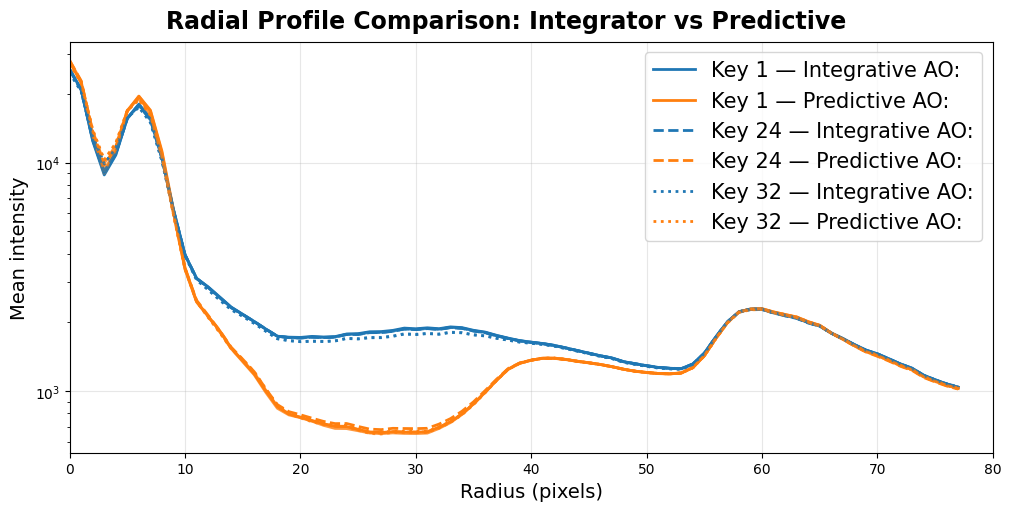

In [57]:
ori_folder = "/home/aosimul/noah/data/ghost_images/long_7ro_20ws/"
name = "_7ro_20ws_"
keys = [1, 24, 32]
batches = ["_1-4", "_5-8"]
datasets = ["int", "pred"]

# ============================================================
# Figure 1: Mean and standard deviation of the science frames
# Rows: Integrator (top), Predictive (bottom)
# Columns: Mean and std for each batch
# ============================================================

fig, axes = plt.subplots(2, 4, figsize=(12, 6), constrained_layout=True)

fig.suptitle("Mean and Standard Deviation Across Keys", fontsize=18, fontweight="bold")

for i, ds in enumerate(datasets):
    for j, batch in enumerate(batches):

        # Load each key and calculate its mean science frame
        key_means = []

        for key in keys:
            filename = f"{ds}{name}{key}key{batch}.npy"
            stack = np.load(f"{ori_folder}{filename}")

            key_means.append(np.mean(stack, axis=0))

        # Mean and std across keys, pixel by pixel
        key_means = np.stack(key_means, axis=0)

        mean = np.mean(key_means, axis=0)
        std = np.std(key_means, axis=0)

        # Column positions: 0,1 for batch 1; 2,3 for batch 2
        col = j * 2

        im0 = axes[i, col].imshow(np.log10(np.maximum(mean, 1e-10)))
        axes[i, col].set_title(f"{ds.upper()} — Batch {batch}: Mean")
        fig.colorbar(im0, ax=axes[i, col], fraction=0.046, pad=0.04)

        im1 = axes[i, col + 1].imshow(std, vmin=0)
        axes[i, col + 1].set_title(f"{ds.upper()} — Batch {batch}: Std")
        fig.colorbar(im1, ax=axes[i, col + 1], fraction=0.046, pad=0.04)

    # Row label
    axes[i, 0].set_ylabel(titling(ds), fontsize=14, fontweight="bold")

plt.show()


# ============================================================
# Figure 2: Radial profiles for all keys
# Rows: Integrator (top), Predictive (bottom)
# Each key has a different line color; line style distinguishes
# the two batches.
# ============================================================
# ============================================================
# Radial profiles: Integrator vs Predictive on the same axes
# One subplot per batch; colors distinguish keys
# Solid = Integrator, dashed = Predictive
# ============================================================

fig, axes = plt.subplots(1, 1, figsize=(10, 5), sharey=True, constrained_layout=True)

fig.suptitle(
    "Radial Profile Comparison: Integrator vs Predictive",
    fontsize=17,
    fontweight="bold",
)

colors = {
    "int": "tab:blue",
    "pred": "tab:orange",
}

linestyles = {1: "-", 24: "--", 32: ":"}

for j, batch in enumerate(batches):

    for key in keys:
        for ds in ["int", "pred"]:
            filename = f"{ds}{name}{key}key{batch}.npy"
            stack = np.load(f"{ori_folder}{filename}")

            mean = np.mean(stack, axis=0)
            radius, profile, radial_std = radial_profile_pre(mean)

            plt.plot(
                radius,
                profile,
                color=colors[ds],
                linestyle=linestyles[key],
                linewidth=2,
                label=f"Key {key} — {titling(ds)}" if j == 0 else None,
                alpha=None if j == 0 else 0.8,
            )

plt.xlabel("Radius (pixels)", fontsize=14)
plt.yscale("log")
plt.grid(alpha=0.3)
plt.legend(fontsize=15)
plt.xlim(left=0, right=80)

plt.ylabel("Mean intensity", fontsize=14)

plt.show()